In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from dgl.nn.pytorch import GATConv
import dgl
# Graficas
import networkx as nx
import matplotlib.pyplot as plt

import pandas as pd
import numpy as np
import re
import random

from transformers import AutoTokenizer

from sklearn.metrics import f1_score

/home/usuario/prg/anaconda3/envs/dgl-env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device => ",device)

Device =>  cuda


In [ ]:
path ='New Preprocessed/'
target_dataset = "AAEC"

# Training
df_component_train = pd.read_csv(path+"component_train.csv", header=0)[["text_id", "component_tokens", "labels"]]
df_component_train = df_component_train[df_component_train.text_id.str.contains(target_dataset)]
df_component_train["tokens"]= df_component_train.component_tokens.apply(lambda x:re.sub(r'[^\w]', ' ', x).strip().replace(" ", "").lower())

# ----
# Load Link Detection data
# df_link_train = pd.read_csv(path+"relation_train.csv", header=0, index_col=0)[["text_id", "source_tokens", "target_tokens", "labels"]]
# df_link_train = df_link_train[df_link_train.text_id.str.contains(target_dataset)]
# df_link_train["labels"] = np.where(df_link_train["labels"].isna(), 0, 1)
# df_link_train = pd.merge(df_link_train, df_component_train,  how='left', left_on=['text_id'], right_on = ['text_id'])
# print(df_link_train)
# ----

df_relation_train = pd.read_csv(path+"link_train.csv", header=0)[["text_id", "source_tokens", "target_tokens", "labels"]]
df_relation_train = df_relation_train[df_relation_train.text_id.str.contains(target_dataset)]
df_relation_train["source_tokens"]= df_relation_train.source_tokens.apply(lambda x:re.sub(r'[^\w]', ' ', x).strip().replace(" ", "").lower())
df_relation_train["target_tokens"]= df_relation_train.target_tokens.apply(lambda x:re.sub(r'[^\w]', ' ', x).strip().replace(" ", "").lower())
# df_relation_train["labels"] = df_relation_train["labels"].fillna("None")
df_relation_train["labels"] = np.where(df_relation_train["labels"].isna(), 0, 1)
n_links = df_relation_train[df_relation_train.labels == 1].shape[0]

# Validation
df_component_val = pd.read_csv(path+"component_val.csv", header=0)[["text_id", "component_tokens", "labels"]]
df_component_val = df_component_val[df_component_val.text_id.str.contains(target_dataset)]
df_component_val["tokens"]= df_component_val.component_tokens.apply(lambda x:re.sub(r'[^\w]', ' ', x).strip().replace(" ", "").lower())

df_relation_val = pd.read_csv(path+"link_val.csv", header=0)[["text_id", "source_tokens", "target_tokens", "labels"]]
df_relation_val = df_relation_val[df_relation_val.text_id.str.contains(target_dataset)]
df_relation_val["source_tokens"]= df_relation_val.source_tokens.apply(lambda x:re.sub(r'[^\w]', ' ', x).strip().replace(" ", "").lower())
df_relation_val["target_tokens"]= df_relation_val.target_tokens.apply(lambda x:re.sub(r'[^\w]', ' ', x).strip().replace(" ", "").lower())
# df_relation_val["labels"] = df_relation_val["labels"].fillna("None")
df_relation_val["labels"] = np.where(df_relation_val["labels"].isna(), 0, 1)

# Test
df_component_test = pd.read_csv(path+"component_test.csv", header=0)[["text_id", "component_tokens", "labels"]]
df_component_test = df_component_test[df_component_test.text_id.str.contains(target_dataset)]
df_component_test["tokens"]= df_component_test.component_tokens.apply(lambda x:re.sub(r'[^\w]', ' ', x).strip().replace(" ", "").lower())

df_relation_test = pd.read_csv(path+"link_test.csv", header=0)[["text_id", "source_tokens", "target_tokens", "labels"]]
df_relation_test = df_relation_test[df_relation_test.text_id.str.contains(target_dataset)]
df_relation_test["source_tokens"]= df_relation_test.source_tokens.apply(lambda x:re.sub(r'[^\w]', ' ', x).strip().replace(" ", "").lower())
df_relation_test["target_tokens"]= df_relation_test.target_tokens.apply(lambda x:re.sub(r'[^\w]', ' ', x).strip().replace(" ", "").lower())
# df_relation_test["labels"] = df_relation_test["labels"].fillna("None")
df_relation_test["labels"] = np.where(df_relation_test["labels"].isna(), 0, 1)

print(df_relation_val)


       text_id                                      source_tokens  \
0     AAEC_008  alackofwellestablishedprimaryeducationgoeshand...   
1     AAEC_008  governmentshouldguaranteethatallpeoplehaveequa...   
2     AAEC_008  elementaryeducationlikethebaseofaarchitecturei...   
3     AAEC_008                              thisargumentisinvalid   
4     AAEC_008  somemayarguethatuniversitiescansupportthemselv...   
...        ...                                                ...   
6704  AAEC_402         playingsportswillgivegoodeffectsonchildren   
6705  AAEC_402         playingsportswillgivegoodeffectsonchildren   
6706  AAEC_402         playingsportswillgivegoodeffectsonchildren   
6707  AAEC_402         playingsportswillgivegoodeffectsonchildren   
6708  AAEC_402         playingsportswillgivegoodeffectsonchildren   

                                          target_tokens  labels  
0     ifcountriesespeciallythedevelopingcountriesare...       1  
1     ifcountriesespeciallythedevelopin

In [18]:
data = {
    "train": {
        "component": df_component_train,
        "relation": df_relation_train
    },
    "test": {
        "component": df_component_test,
        "relation": df_relation_test
    },
    "val": {
        "component": df_component_val,
        "relation": df_relation_val
    },
}

In [19]:
# init variables
possible_labels = {
    "Premise": 0,
    "Claim": 1,
    "MajorClaim": 2,
}

possible_relations = {
    "None": 0,
    "Link": 1
}

node_id = 0
node_features = list()
node_labels = list()
source_nodes = list()
target_nodes = list()
edge_labels = list()
train_mask = list()
val_mask = list()
test_mask = list()
e_train_mask = list()
e_val_mask = list()
e_test_mask = list()
text_nodes = dict()

In [20]:
model_name = "roberta-base"
max_length = 76
tokenizer = AutoTokenizer.from_pretrained(model_name, add_prefix_space=True, use_fast=False)

In [21]:
for key in data.keys():
    # if key == "test": break
    df_component = data[key]["component"]
    text_ids = df_component.text_id.unique()
    df_relation = data[key]["relation"]

    for num, text_id in enumerate(text_ids):
        # if num == 1: break
        # print(f"Ingresa -> {num} - {text_ids}")
        df_c = df_component[df_component.text_id == text_id]
        df_r = df_relation[df_relation.text_id == text_id]
        components = df_c.to_dict('records')
        relations = df_r.to_dict('records')

        for component in components:
            to_be_token = f"{component['component_tokens']}"
            node_tokenized = tokenizer.encode(to_be_token, padding="max_length", max_length=max_length)
            node_label = possible_labels[component["labels"]]
            node_key = f"{text_id}: {component['tokens']}"
            text_nodes[node_key] = {
                "node_text_id": text_id,
                "node_id": node_id,
                "node_text": component["component_tokens"],
                "node_tokenized": node_tokenized,
                "node_label": node_label
            }
            node_features.append(node_tokenized)

            node_labels.append(node_label)
            train_mask.append(key == "train")
            val_mask.append(key == "val")
            test_mask.append(key == "test")
            node_id = node_id + 1

        for relation in relations:
            source_key = f"{text_id}: {relation['source_tokens']}"
            target_key = f"{text_id}: {relation['target_tokens']}"
            # edge_label = possible_relations[relation["labels"]]
            edge_label = relation["labels"]
            source_nodes.append(text_nodes[source_key]["node_id"])
            target_nodes.append(text_nodes[target_key]["node_id"])
            edge_labels.append(edge_label)
            e_train_mask.append(key == "train")
            e_val_mask.append(key == "val")
            e_test_mask.append(key == "test")

In [22]:
# Creating graphs
g = dgl.graph((source_nodes, target_nodes))
g.ndata['feat'] = torch.Tensor(node_features)
g.ndata['label'] = torch.Tensor(node_labels).to(torch.long)
g.edata['label'] = torch.Tensor(edge_labels).to(torch.long)
g.ndata["train_mask"] = torch.Tensor(train_mask).bool()
g.ndata["val_mask"] = torch.Tensor(val_mask).bool()
g.ndata["test_mask"] = torch.Tensor(test_mask).bool()
g.edata["train_mask"] = torch.Tensor(e_train_mask).bool()
g.edata["val_mask"] = torch.Tensor(e_val_mask).bool()
g.edata["test_mask"] = torch.Tensor(e_test_mask).bool()
g = g.int().to(device)

print("Grafo ---> ", g)
node = 0
print("feat: ", g.ndata['feat'][node])
print("label: ", g.ndata['label'][node])
print("train_mask: ", g.ndata['train_mask'][node])
print("val_mask: ", g.ndata['val_mask'][node])
print("test_mask: ", g.ndata['test_mask'][node])
print("test_mask: ", g.ndata['test_mask'][node])
print("----------- EDGE ----------------")
print("label: ", g.edata['label'][:20])

n = df_relation_train[df_relation_train.labels != 1].shape[0]

del df_component_train
del df_relation_train
del df_relation_test
del df_component_test
del df_component_val
del df_relation_val
del data
del source_nodes
del target_nodes

Grafo --->  Graph(num_nodes=6089, num_edges=98471,
      ndata_schemes={'feat': Scheme(shape=(76,), dtype=torch.float32), 'label': Scheme(shape=(), dtype=torch.int64), 'train_mask': Scheme(shape=(), dtype=torch.bool), 'val_mask': Scheme(shape=(), dtype=torch.bool), 'test_mask': Scheme(shape=(), dtype=torch.bool)}
      edata_schemes={'label': Scheme(shape=(), dtype=torch.int64), 'train_mask': Scheme(shape=(), dtype=torch.bool), 'val_mask': Scheme(shape=(), dtype=torch.bool), 'test_mask': Scheme(shape=(), dtype=torch.bool)})
feat:  tensor([0.0000e+00, 5.2000e+01, 1.9700e+02, 2.4051e+04, 5.5000e+01, 3.5850e+03,
        7.0000e+00, 4.6010e+03, 1.4800e+02, 2.2700e+03, 1.2650e+03, 2.0000e+00,
        1.0000e+00, 1.0000e+00, 1.0000e+00, 1.0000e+00, 1.0000e+00, 1.0000e+00,
        1.0000e+00, 1.0000e+00, 1.0000e+00, 1.0000e+00, 1.0000e+00, 1.0000e+00,
        1.0000e+00, 1.0000e+00, 1.0000e+00, 1.0000e+00, 1.0000e+00, 1.0000e+00,
        1.0000e+00, 1.0000e+00, 1.0000e+00, 1.0000e+00, 1.0000e

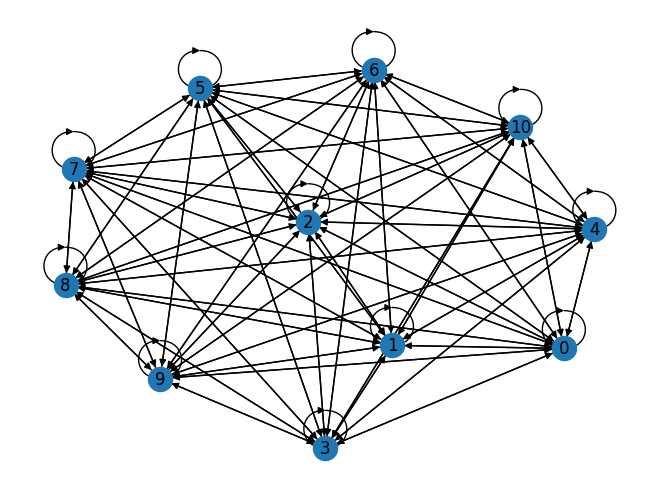

In [ ]:
# convierte de DGL graph → NetworkX graph
# nx_g = g.cpu().to_networkx()

# nx.draw(nx_g, with_labels=True)
# plt.show()

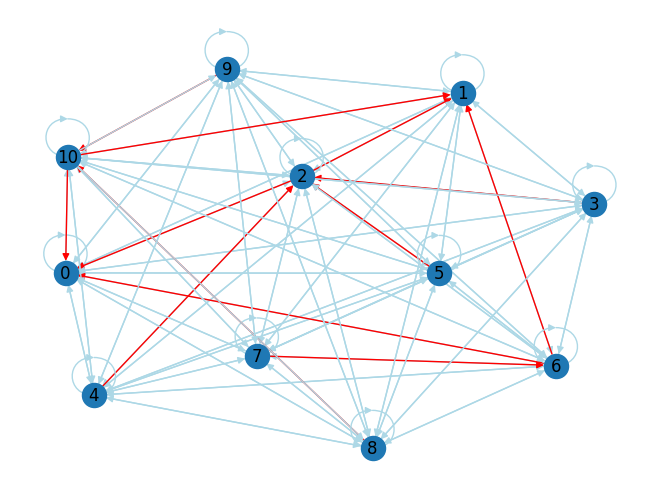

In [ ]:
# edge_colors = []

# for u, v, e in nx_g.edges(data=True):
#     if g.edata['label'][e['id']] == 1:
#         edge_colors.append('red')
#     else:
#         edge_colors.append('lightblue')

# nx.draw(nx_g, with_labels=True, edge_color=edge_colors)
# plt.show()

In [27]:
# Modelo GNN
class GATLayer(nn.Module):
    def __init__(self, g, in_dim, out_dim):
        super(GATLayer, self).__init__()
        self.g = g      
        # equation (1)
        self.fc = nn.Linear(in_dim, out_dim, bias=False)
        # self.fc = nn.LSTM(in_dim, out_dim, bidirectional=False)
        # equation (2)
        self.attn_fc = nn.Linear(2 * out_dim, 1, bias=False)
        # self.attn_fc = nn.LSTM(2*out_dim, 1, bias=False)
        self.reset_parameters() #Agregué por que en el doc esta de esa manera

    def reset_parameters(self):
        """Reinitialize learnable parameters."""
        gain = nn.init.calculate_gain('relu')
        nn.init.xavier_normal_(self.fc.weight, gain=gain)
        nn.init.xavier_normal_(self.attn_fc.weight, gain=gain)

    def edge_attention(self, edges):
        # edge UDF for equation (2)
        z = torch.cat([edges.src['z'], edges.dst['z']], dim=1)
        # a = self.attn_fc(z)[0]
        a = self.attn_fc(z)
        return {'e': F.leaky_relu(a)}

    def message_func(self, edges):
        # message UDF for equation (3) & (4)
        return {'z': edges.src['z'], 'e': edges.data['e']}

    def reduce_func(self, nodes):
        # reduce UDF for equation (3) & (4)
        # equation (3)
        alpha = F.softmax(nodes.mailbox['e'], dim=1)
        # equation (4)
        h = torch.sum(alpha * nodes.mailbox['z'], dim=1)
        return {'h': h}

    def forward(self, h):
        # equation (1)
        z = self.fc(h)
        # self.g.ndata['z'] = z[0]
        self.g.ndata["z"] = z
        # equation (2)
        self.g.apply_edges(self.edge_attention)
        # equation (3) & (4)
        self.g.update_all(self.message_func, self.reduce_func)
        return self.g.ndata.pop('h')
        
class MultiHeadGATLayer(nn.Module):
    def __init__(self, g, in_dim, out_dim, num_heads, merge='cat'):
        super(MultiHeadGATLayer, self).__init__()
        self.heads = nn.ModuleList()
        for _ in range(num_heads):
            self.heads.append(GATLayer(g, in_dim, out_dim))
        self.merge = merge

    def forward(self, h):
        head_outs = [attn_head(h) for attn_head in self.heads]
        if self.merge == 'cat':
            # concat on the output feature dimension (dim=1)
            return torch.cat(head_outs, dim=1)
        else:
            # merge using average
            return torch.mean(torch.stack(head_outs))
            
class GAT(nn.Module):
    def __init__(self, g, in_dim, hidden_dim, out_dim, num_heads):
        super(GAT, self).__init__()
        self.g = g
        self.layer1 = MultiHeadGATLayer(g, in_dim, hidden_dim, num_heads)
        # Be aware that the input dimension is hidden_dim*num_heads since
        # multiple head outputs are concatenated together. Also, only
        # one attention head in the output layer.
        self.layer2 = MultiHeadGATLayer(g, int(hidden_dim * num_heads), out_dim, 1)
        self.dropout = nn.Dropout(0.5)

    def forward(self, h):
        h = self.dropout(h)
        h = self.layer1(h)
        h = F.relu(h)
        h = self.dropout(h)
        h = self.layer2(h)
        h = F.relu(h)
        return h
        
class MLPPredictor(nn.Module):
    def __init__(self, in_features, out_classes):
        super().__init__()
        # self.Wg = nn.LSTM(2*in_features, in_features)
        # self.Wl = nn.LSTM(2*76, in_features)
        # self.W2 = nn.Linear(2*in_features, out_classes)
        self.Wg = nn.Linear(2*in_features, in_features)
        self.Wl = nn.Linear(2*76, in_features)
        self.W2 = nn.Linear(2*in_features, out_classes)

    def apply_edges(self, edges):
        h_u = edges.src['h']
        f_u = edges.src['feat']
        h_v = edges.dst['h']
        f_v = edges.dst['feat']
        # lang = self.Wl(torch.cat([f_u, f_v], 1))[0]
        # graph = self.Wg(torch.cat([h_u, h_v], 1))[0]
        lang = self.Wl(torch.cat([f_u, f_v], 1))
        graph = self.Wg(torch.cat([h_u, h_v], 1))
        score = self.W2(torch.cat([lang, graph], 1))
        return {'score': score}

    def forward(self, graph, h):
        # h contains the node representations computed from the GNN defined
        # in the node classification section (Section 5.1).
        with graph.local_scope():
            graph.ndata['h'] = h
            graph.apply_edges(self.apply_edges)
            return graph.edata['score']

class Model(nn.Module):
    def __init__(self, g, in_dim, hidden_dim, out_dim, num_heads):
        super().__init__()
        self.gat = GAT(g, in_dim, hidden_dim, hidden_dim, num_heads)
        self.pred = MLPPredictor(hidden_dim, out_dim)
    def forward(self, x):
        h = self.gat(x)
        return self.pred(g, h)
        # return h

In [24]:
def set_seeds(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    dgl.random.seed(seed)
    torch.use_deterministic_algorithms = True

def evaluate(g, features, labels, mask, model):
  model.eval()
  with torch.no_grad():
    logits = model(features)
    logits = logits[mask]
    labels = labels[mask]
    _, indices = torch.max(logits, dim=1)
    f1 = f1_score(average="micro", y_true=list(labels.to("cpu")), y_pred=list(indices.to("cpu")))
    f1_macro = f1_score(average="macro", y_true=list(labels.to("cpu")), y_pred=list(indices.to("cpu")))
    f1_link = f1_score(average="binary", pos_label=1, y_true=list(labels.to("cpu")), y_pred=list(indices.to("cpu")))
    return {"f1_micro": f1, "f1_macro": f1_macro, "f1_link": f1_link}

In [31]:
# Training GNN
# NUM_EPOCHS = 250
NUM_EPOCHS = 1
# seeds = [0, 9, 27, 42, 1871, 1977, 1994, 2000, 2020, 2023]
seeds = [0]
macro = list()
f1_link = list()
node_features = g.ndata['feat']
edge_label = g.edata['label']
train_mask = g.edata['train_mask']
val_mask = g.edata["val_mask"]
n_train_mask = g.ndata['train_mask']
n_val_mask = g.edata["val_mask"]

path=f"Model/model.pth"

class_weights = torch.Tensor([1.0, float(n/n_links)]).to(device)

for i, seed in enumerate(seeds):
  print(f"{i+1}/{len(seeds)}")
  set_seeds(seed)
  in_size = node_features.shape[1]
  out_size = 2
  # model_edge = Model(g, in_size, 20*in_size, out_size, 2).to(device)
  model_edge = Model(g, in_size, 32, out_size, 2).to(device)
  loss_fcn = nn.CrossEntropyLoss(weight=class_weights)
  opt = torch.optim.Adam(model_edge.parameters(), lr=2e-3, weight_decay=0.01)
  best_metric = 0
  best_loss = 0
  for epoch in range(NUM_EPOCHS):
    pred = model_edge(node_features)
    loss = loss_fcn(pred[train_mask], edge_label[train_mask].to(torch.long))
    opt.zero_grad()
    loss.backward()
    opt.step()
    acc = evaluate(g, node_features, edge_label, val_mask, model_edge)
    f_macro = acc["f1_link"]
    if best_loss == 0:
      best_loss = loss
    if f_macro >= best_metric:
      if f_macro == best_metric and loss > best_loss:
        pass
      else:
        best_metric = f_macro
        best_loss = loss
        torch.save(model_edge.state_dict(), path)
    print(f"Epoch {epoch+1}, loss: {loss}, metrics: {acc}")
  model_edge.load_state_dict(torch.load(path))
  acc = evaluate(g, node_features, edge_label, g.edata["test_mask"], model_edge)
  macro.append(acc["f1_macro"])
  f1_link.append(acc["f1_link"])
  print(f"\nModel test metrics: {acc} \n")

1/1
Epoch 1, loss: 1789.818603515625, metrics: {'f1_micro': 0.43970785511998806, 'f1_macro': 0.3587360664272651, 'f1_link': 0.13086705202312138}


/tmp/ipykernel_50032/3178049979.py:48: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_edge.load_state_dict(torch.load(path))



Model test metrics: {'f1_micro': 0.36009879765122565, 'f1_macro': 0.30674221073552443, 'f1_link': 0.11441470493389229} 



### Exemplo. Só para revisar o modelo

In [14]:
from dgl import DGLGraph
from dgl.data import citation_graph as citegrh


def load_cora_data():
    data = citegrh.load_cora()
    g = data[0]
    mask = torch.BoolTensor(g.ndata["train_mask"])
    return g, g.ndata["feat"], g.ndata["label"], mask

In [ ]:
import time

import numpy as np

g, features, labels, mask = load_cora_data()
g = g.to(device)
features = features.to(device)
labels = labels.to(device)
mask = mask.to(device)

# create the model, 2 heads, each head has hidden size 8
net = Model(g, in_dim=features.size()[1], hidden_dim=8, out_dim=7, num_heads=2).to(device)

# create optimizer
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

# main loop
dur = []
for epoch in range(30):
    if epoch >= 3:
        t0 = time.time()

    logits = net(features)
    logp = F.log_softmax(logits, 1)
    loss = F.nll_loss(logp[mask], labels[mask])

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch >= 3:
        dur.append(time.time() - t0)

    print(
        "Epoch {:05d} | Loss {:.4f} | Time(s) {:.4f}".format(
            epoch, loss.item(), np.mean(dur)
        )
    )

  NumNodes: 2708
  NumEdges: 10556
  NumFeats: 1433
  NumClasses: 7
  NumTrainingSamples: 140
  NumValidationSamples: 500
  NumTestSamples: 1000
Done loading data from cached files.


RuntimeError: input.size(-1) must be equal to input_size. Expected 152, got 2866